In [23]:
import torch
print(torch.__version__)

2.6.0+cpu


In [24]:
import torch_geometric
from torch_geometric.utils import from_networkx, add_self_loops, degree
from torch_geometric.nn import MessagePassing
import torch_geometric.transforms as T
from torch_geometric.data import DataLoader
from torch_geometric.loader import NeighborSampler
import torch.nn as nn
import torch as th
import torch.nn.functional as F
import networkx as nx
import pandas as pd
import socket
import struct
import random
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
X_test = pd.read_csv(r"") #X_test.csv upload path

In [33]:
unique, counts = np.unique(X_test.y.cpu().numpy(), return_counts=True)
print(dict(zip(unique, counts)))


AttributeError: 'DataFrame' object has no attribute 'y'

In [26]:
cols_to_norm = ['LONGEST_FLOW_PKT', 'RETRANSMITTED_IN_PKTS', 'MAX_IP_PKT_LEN', 'TCP_WIN_MAX_IN', 'RETRANSMITTED_OUT_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'OUT_PKTS', 'DURATION_OUT', 'IN_PKTS', 'FLOW_DURATION_MILLISECONDS', 'MIN_IP_PKT_LEN', 'NUM_PKTS_512_TO_1024_BYTES', 'RETRANSMITTED_IN_BYTES', 'DURATION_IN', 'SHORTEST_FLOW_PKT', 'IN_BYTES', 'DST_TO_SRC_AVG_THROUGHPUT', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_SECOND_BYTES', 'TCP_WIN_MAX_OUT', 'SRC_TO_DST_AVG_THROUGHPUT', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'OUT_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_UP_TO_128_BYTES', 'MAX_TTL', 'MIN_TTL']

In [27]:
class EGraphSAGEConv(MessagePassing):
    def __init__(self, node_in_channels, edge_in_channels, out_channels):
        super(EGraphSAGEConv, self).__init__(aggr='mean')  # mean aggregation
        self.lin_node = nn.Linear(node_in_channels, out_channels)
        self.lin_edge = nn.Linear(edge_in_channels, out_channels)
        self.lin_update = nn.Linear(node_in_channels + out_channels, out_channels) # out_channels * 2

    def forward(self, x, edge_index, edge_attr):
        # x: Node features, edge_attr: Edge features, edge_index: Connectivity
        edge_index, _ = add_self_loops(edge_index, num_nodes=x.size(0))

        if edge_attr is not None:
            if edge_attr.size(0) != edge_index.size(1):
                loop_attr = th.zeros((edge_index.size(1) - edge_attr.size(0), edge_attr.size(1))).to(edge_attr.device)
                edge_attr = th.cat([edge_attr, loop_attr], dim=0)
        else:
            print("edge_attr is unexist")
        
        # Propagate and aggregate neighbor information
        return self.propagate(edge_index, x=x, edge_attr=edge_attr)

    def message(self, x_j, edge_attr):
        # x_j represents the adjacent nodes of x
        # Compute messages by combining node and edge features
        return self.lin_node(x_j) + self.lin_edge(edge_attr)

    def update(self, aggr_out, x):
        # Update node features after message passing
        return self.lin_update(th.cat([x, aggr_out], dim=1))

class MLPPredictor(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(MLPPredictor, self).__init__()
        self.lin = nn.Linear(in_channels * 2, out_channels)

    def forward(self, data, z):
        row, col = data.edge_index
        # Concatenate the features of source and target nodes for each edge
        edge_feat = th.cat([z[row], z[col]], dim=1)
        return self.lin(edge_feat)

class EGraphSAGE(nn.Module):
    def __init__(self, node_in_channels, edge_in_channels, hidden_channels, out_channels):
        super(EGraphSAGE, self).__init__()
        self.conv1 = EGraphSAGEConv(node_in_channels, edge_in_channels, hidden_channels)
        self.conv2 = EGraphSAGEConv(hidden_channels, edge_in_channels, hidden_channels)
        self.mlp_predictor = MLPPredictor(hidden_channels, out_channels)

    def forward(self, data):
        x, edge_index, edge_attr = data.x, data.edge_index, data.edge_attr
        x = F.relu(self.conv1(x, edge_index, edge_attr))
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index, edge_attr)
        return self.mlp_predictor(data, x)

In [28]:
device = th.device("cuda:0" if th.cuda.is_available() else "cpu")
print(device)

cpu


In [29]:
th.cuda.empty_cache()

In [30]:
from sklearn.preprocessing import LabelEncoder

test_le = LabelEncoder()
X_test['Attack'] = test_le.fit_transform(X_test['Attack'])
test_class_map = test_le.classes_
print(test_class_map)
print("Attack label mapping:", dict(zip(test_class_map, range(len(test_class_map)))))

['Benign' 'DDoS attack']
Attack label mapping: {'Benign': 0, 'DDoS attack': 1}


In [31]:
X_test['h'] = X_test[ cols_to_norm ].values.tolist()

G_nx_test = nx.from_pandas_edgelist(X_test, "saddr", "daddr", ['h', 'Label', 'Attack'], create_using=nx.MultiDiGraph())

G_pyg_test = from_networkx(G_nx_test)

test_num_nodes = G_pyg_test.num_nodes
test_num_edges = G_pyg_test.num_edges

G_pyg_test.x = th.ones(test_num_nodes, len(X_test['h'].iloc[0]))

test_edge_attr_list = []
test_edge_label_list = []
test_edge_class_list = []

for u, v, key, data in G_nx_test.edges(keys=True, data=True):
    test_edge_attr_list.append(data['h']) 
    test_edge_label_list.append(data['Label']) 
    test_edge_class_list.append(data['Attack'])

G_pyg_test.edge_attr = th.tensor(test_edge_attr_list, dtype=th.float32)
G_pyg_test.edge_label = th.tensor(test_edge_label_list, dtype=th.long)
G_pyg_test.edge_class = th.tensor(test_edge_class_list, dtype=th.long)

print("Number of edges in G_pyg_test:", G_pyg_test.num_edges)
print("Number of node in G_pyg_test:", G_pyg_test.num_nodes)
print("Shape of node in G_pyg_test:", G_pyg_test.x.shape)
print("Shape of edge attr in G_pyg_test:", G_pyg_test.edge_attr.shape)
print("Shape of edge label in G_pyg_test:", G_pyg_test.edge_label.shape)
print("Shape of edge class in G_pyg_test:", G_pyg_test.edge_class.shape)

Number of edges in G_pyg_test: 1112216
Number of node in G_pyg_test: 718893
Shape of node in G_pyg_test: torch.Size([718893, 28])
Shape of edge attr in G_pyg_test: torch.Size([1112216, 28])
Shape of edge label in G_pyg_test: torch.Size([1112216])
Shape of edge class in G_pyg_test: torch.Size([1112216])


In [ ]:
from torch_geometric.utils import subgraph
from torch_geometric.data import Data

def compute_accuracy(pred, labels):
    return (pred.argmax(1) == labels).float().mean().item()

new_model_2 = EGraphSAGE(node_in_channels=G_pyg_test.num_node_features, 
                       edge_in_channels=G_pyg_test.num_edge_features,
                       hidden_channels=128, 
                       out_channels=2).to(device)


new_model_2.load_state_dict(th.load(r"", map_location=th.device('cpu'))) #upload gnn model weights .pth file


def generate_edge_based_batches_with_node_expansion(graph, batch_size, min_nodes):
    num_edges = graph.edge_index.size(1) 
    edge_indices = th.arange(num_edges)  
    num_edges_processed = 0
    
    while num_edges_processed < num_edges:
        # Select a batch of edges
        batch_edge_indices = edge_indices[num_edges_processed : min(num_edges_processed + batch_size, num_edges)]
        edge_index = graph.edge_index[:, batch_edge_indices]
        
        # Update the number of edges processed
        num_edges_processed += batch_size
        
        # Get the unique nodes associated with these edges
        batch_nodes = th.cat([edge_index[0], edge_index[1]]).unique()

        # Check if the batch has enough unique nodes
        while batch_nodes.size(0) < min_nodes:
            # Sample additional neighboring nodes to ensure diversity
            additional_edges = int(batch_size / 8)  # Ensure additional_edges is an integer
            batch_edge_indices = th.cat([batch_edge_indices, edge_indices[num_edges_processed : min(num_edges_processed + additional_edges, num_edges)]])
            edge_index = graph.edge_index[:, batch_edge_indices]
            batch_nodes = th.cat([edge_index[0], edge_index[1]]).unique()
            num_edges_processed += additional_edges

            # Avoid potential infinite loops by breaking if no more edges can be added
            if num_edges_processed >= num_edges:
                break

        # Create subgraph from the selected nodes and edges
        edge_index, _, edge_mask = subgraph(batch_nodes, graph.edge_index, relabel_nodes=True, return_edge_mask=True)

        # Use edge_mask to select edge attributes and labels
        edge_attr = graph.edge_attr[edge_mask]
        edge_label = graph.edge_label[edge_mask]
        edge_class = graph.edge_class[edge_mask]

        yield batch_nodes, edge_index, edge_attr, edge_label, edge_class


new_model_2.eval()

all_test_preds = []
all_test_labels = []
all_test_classes = []
attack_class_performance = {attack_type: {'correct': 0, 'incorrect': 0} for attack_type in test_class_map}

batch_size = 1024

print("inference start")
with th.no_grad():
    for batch_idx, (batch_nodes, edge_index, edge_attr, edge_label, edge_class) in enumerate(generate_edge_based_batches_with_node_expansion(G_pyg_test, batch_size, 20)):
        # print(f"Processing batch {batch_idx} with {batch_nodes.size(0)} nodes and {edge_index.size(1)} edges")
        batch = Data(x=G_pyg_test.x[batch_nodes], edge_index=edge_index, edge_attr=edge_attr, edge_label=edge_label)
        
        if batch.edge_index.size(1) == 0 or batch.edge_label.size(0) == 0:
            print(f"Warning: Empty batch at batch {batch_idx}")
            continue
            
        if batch is None or batch.num_nodes == 0:
            print(f"Warning: Empty batch at Batch {batch_idx}")
            continue

        if th.isnan(batch.x).any() or th.isinf(batch.x).any() or th.isnan(batch.edge_attr).any() or th.isinf(batch.edge_attr).any():
            print(f"Warning: batch x and edge_attr contains NaN or Inf at Batch {batch_idx}")
            continue
            
        try:
            batch = batch.to(device)
        except Exception as batch_error:
            print(f"Error moving batch to device at Batch {batch_idx}: {batch_error}")
            continue
        
        try:
            out = new_model_2(batch)

            if th.isnan(out).any() or th.isinf(out).any():
                print(f"Warning: out contains NaN or Inf at Batch {batch_idx}")
                continue 
            
            all_test_preds.append(out)
            all_test_labels.append(edge_label)
            all_test_classes.append(edge_class)

            pred = out.argmax(dim=1) 

            for i in range(len(pred)):
                true_label = edge_label[i].item()
                predicted_label = pred[i].item()
                attack_type = test_le.inverse_transform([edge_class[i].item()])[0] 

                if true_label == 0 and attack_type != 'Benign':
                    print('this sample is Benign but label is wrong')
                
                if true_label == predicted_label:
                    attack_class_performance[attack_type]['correct'] += 1
                else:
                    attack_class_performance[attack_type]['incorrect'] += 1
        except Exception as forward_error:
            print(f"Error during forward/backward pass at Batch {batch_idx}: {forward_error}")
            continue

print("inference done")
all_test_preds = th.cat(all_test_preds).to(device)
all_test_labels = th.cat(all_test_labels).to(device)
all_test_classes = th.cat(all_test_classes).to(device)

test_accuracy = compute_accuracy(all_test_preds, all_test_labels)
print(f'Test Accuracy: {test_accuracy:.4f}')

inference start
inference done
Test Accuracy: 0.5486


In [ ]:
from sklearn.metrics import confusion_matrix

pred_labels = all_test_preds.argmax(dim=1)

pred_labels = pred_labels.cpu()
all_test_labels = all_test_labels.cpu()

cm = confusion_matrix(all_test_labels, pred_labels)

TN, FP, FN, TP = cm.ravel()

print(f'True Positives (TP): {TP}')
print(f'False Positives (FP): {FP}')
print(f'True Negatives (TN): {TN}')
print(f'False Negatives (FN): {FN}')

accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1 Score: {f1_score:.4f}')


True Positives (TP): 100795
False Positives (FP): 45546
True Negatives (TN): 510643
False Negatives (FN): 457563
Accuracy: 0.5486
Precision: 0.6888
Recall: 0.1805
F1 Score: 0.2861


: 

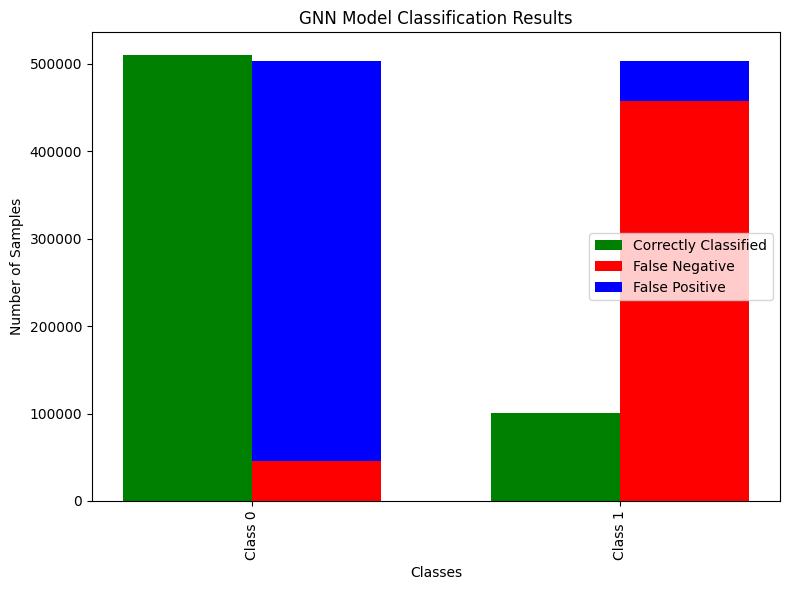

: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Compute Confusion Matrix
pred_labels = all_test_preds.argmax(dim=1).cpu()
all_test_labels = all_test_labels.cpu()
cm = confusion_matrix(all_test_labels, pred_labels)

# Extract true positives, false positives, false negatives, and true negatives
true_labels = np.diag(cm)  # Correctly predicted labels
false_negatives = cm.sum(axis=1) - true_labels  # Missed positives
false_positives = cm.sum(axis=0) - true_labels  # Incorrectly predicted as positive

# Plot Bar Chart
fig, ax = plt.subplots(figsize=(8, 6))
width = 0.35
pos = np.arange(len(true_labels))

# Correctly classified samples (Green)
p1 = plt.bar(pos, true_labels, width, color='g', label='Correctly Classified')

# False negatives (Red)
p2 = plt.bar(pos + width, false_negatives, width, color='r', label='False Negative')

# False positives (Blue)
p3 = plt.bar(
    pos + width,
    false_positives,
    width,
    bottom=false_negatives,
    color='b',
    label='False Positive'
)

# Customize plot
ax.set_xticks(pos + width / 2)
ax.set_xticklabels([f'Class {i}' for i in range(len(true_labels))], rotation='vertical')
ax.set_title('GNN Model Classification Results')
ax.set_xlabel('Classes')
ax.set_ylabel('Number of Samples')
plt.legend()
plt.tight_layout()

# Show & Save
plt.show()



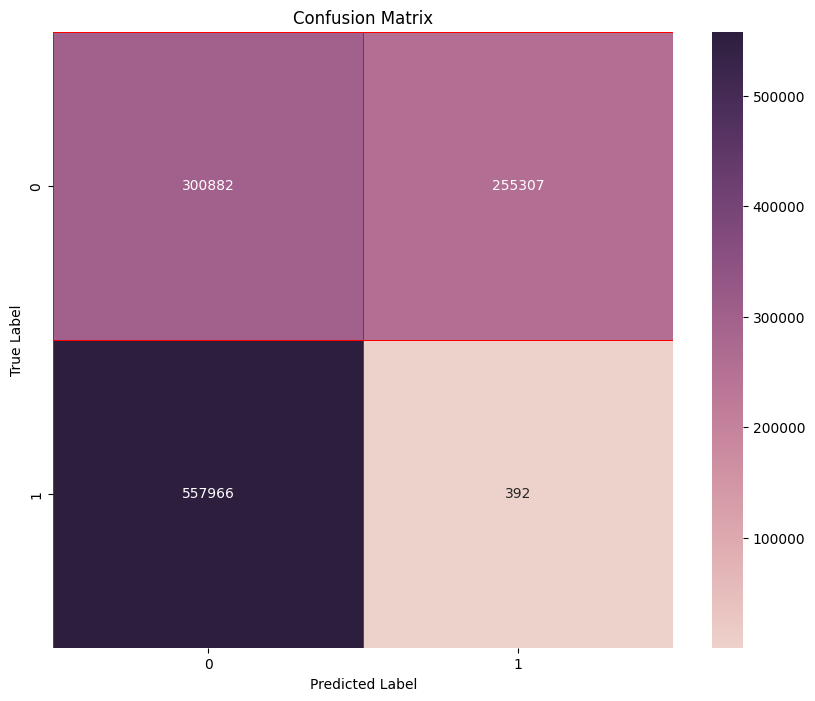

: 

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Compute Confusion Matrix
pred_labels = all_test_preds.argmax(dim=1)
pred_labels = pred_labels.cpu()
all_test_labels = all_test_labels.cpu()

cm = confusion_matrix(all_test_labels, pred_labels)

# Plot Confusion Matrix
f,ax=plt.subplots(figsize=(10,8))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax,cmap=sns.cubehelix_palette(as_cmap=True))
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()


Accuracy: 0.5486
Precision: 0.6082
Recall: 0.5486
F1 Score: 0.4776

Normalized Confusion Matrix:
[[0.92 0.08]
 [0.82 0.18]]


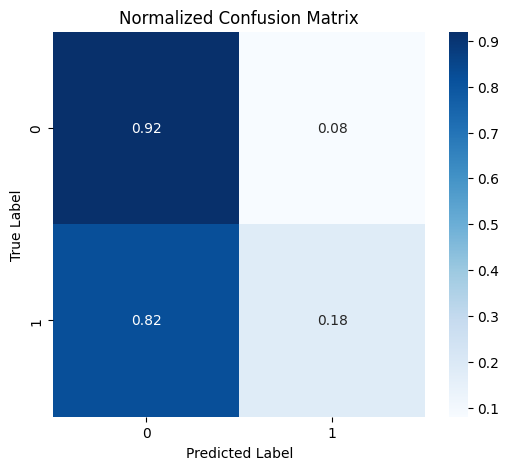

: 

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Convert tensors to CPU and NumPy arrays
pred_labels = all_test_preds.argmax(dim=1).cpu().numpy()
true_labels = all_test_labels.cpu().numpy()

# Compute Confusion Matrix
cm = confusion_matrix(true_labels, pred_labels)

# Normalize Confusion Matrix
cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True)
cm_normalized = np.round(cm_normalized, 2)  # Round values for cleaner display

# Compute Metrics
accuracy = accuracy_score(true_labels, pred_labels)
precision = precision_score(true_labels, pred_labels, average='weighted', zero_division=0)
recall = recall_score(true_labels, pred_labels, average='weighted', zero_division=0)
f1 = f1_score(true_labels, pred_labels, average='weighted', zero_division=0)

# Print Performance Metrics
print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1 Score: {f1:.4f}')
print('\nNormalized Confusion Matrix:')
print(cm_normalized)

# Plot Normalized Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues')

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Normalized Confusion Matrix')

plt.show()


: 